In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sc

In [36]:
df = pd.read_csv('employee_attrition_1000_rows_simple.csv')

In [37]:
df.shape

(1000, 7)

In [38]:
df.head(2)

,Age,MonthlyIncome,YearsAtCompany,MonthlyHours,JobSatisfaction,OverTime,Attrition
0,24,80798,1,204,3,No,0
1,51,56647,11,190,2,No,0


In [39]:
df['Monthly_Salary_level'] = pd.cut(
    df['MonthlyIncome'],
    bins=[30000,50000,100000,float("inf")],
    labels=['Low',"Medium","High"]
)

In [40]:
df.head(2)

,Age,MonthlyIncome,YearsAtCompany,MonthlyHours,JobSatisfaction,OverTime,Attrition,Monthly_Salary_level
0,24,80798,1,204,3,No,0,Medium
1,51,56647,11,190,2,No,0,Medium


In [41]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['OverTime'] = le.fit_transform(df['OverTime'])
df['Monthly_Salary_level'] = le.fit_transform(df['Monthly_Salary_level'])

In [42]:
df.head()

,Age,MonthlyIncome,YearsAtCompany,MonthlyHours,JobSatisfaction,OverTime,Attrition,Monthly_Salary_level
0,24,80798,1,204,3,0,0,2
1,51,56647,11,190,2,0,0,2
2,47,65454,3,175,3,0,0,2
3,38,53978,15,165,4,0,0,2
4,38,51933,13,165,4,1,0,2


In [43]:
df.skew(numeric_only=True)

Age                    -0.032042
MonthlyIncome           0.038794
YearsAtCompany          0.527606
MonthlyHours            0.064507
JobSatisfaction        -0.017546
OverTime                1.119865
Attrition               1.278396
Monthly_Salary_level   -0.005186
dtype: float64

In [44]:
df.describe()

,Age,MonthlyIncome,YearsAtCompany,MonthlyHours,JobSatisfaction,OverTime,Attrition,Monthly_Salary_level
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000
mean,40.612000,54813.438000,7.378000,175.957000,3.005000,0.25600,0.231000,1.802000
std,11.546808,17892.940505,5.920994,21.681449,1.406041,0.43664,0.421683,0.599296
min,21.000000,18000.000000,0.000000,120.000000,1.000000,0.00000,0.000000,0.000000
25%,30.000000,42643.500000,2.000000,161.000000,2.000000,0.00000,0.000000,1.000000
50%,41.000000,55062.000000,6.000000,176.000000,3.000000,0.00000,0.000000,2.000000
75%,51.000000,66443.750000,12.000000,191.000000,4.000000,1.00000,0.000000,2.000000
max,60.000000,112219.000000,20.000000,240.000000,5.000000,1.00000,1.000000,3.000000


<Axes: xlabel='MonthlyIncome', ylabel='Count'>

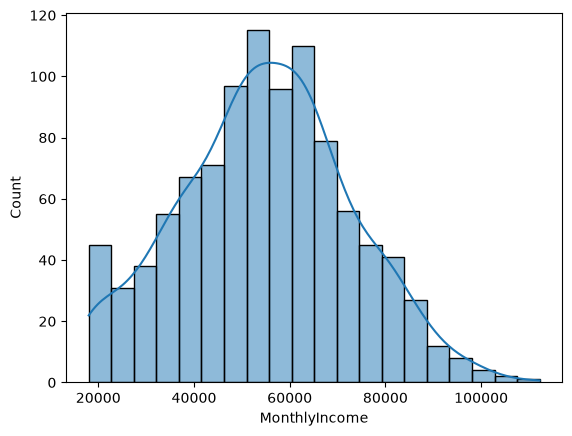

In [45]:
sc.histplot(df['MonthlyIncome'],kde=True)

In [46]:
X = df.drop('Attrition',axis = 1)
Y = df['Attrition']

In [47]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [48]:
from sklearn.preprocessing import StandardScaler
scal = StandardScaler()

X_train_scal = scal.fit_transform(X_train)
X_test_scal = scal.transform(X_test)

In [49]:
from sklearn.tree import DecisionTreeClassifier

model_tree = DecisionTreeClassifier(class_weight='balanced')
model_tree.fit(X_train_scal,y_train)

,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, ev

In [50]:
pre_tree = model_tree.predict(X_test_scal)

In [89]:
pre_tree = (pre_tree > 0.5).astype(int)

In [90]:
from sklearn.metrics import accuracy_score,f1_score,classification_report

In [91]:
accuracy_score(y_test,pre_tree)

0.68

In [88]:
print(classification_report(y_test,pre_tree))

              precision    recall  f1-score   support

           0       0.82      0.76      0.79       159
           1       0.28      0.37      0.32        41

    accuracy                           0.68       200
   macro avg       0.55      0.56      0.55       200
weighted avg       0.71      0.68      0.69       200



In [54]:
from sklearn.model_selection import cross_val_score

cv_sc = cross_val_score(model_tree,X,Y,cv=5,scoring='accuracy')

In [55]:
cv_sc

array([0.7  , 0.68 , 0.66 , 0.68 , 0.675])

In [56]:
cv_sc.mean()

np.float64(0.679)

In [57]:
from sklearn.ensemble import RandomForestClassifier

random = RandomForestClassifier(n_estimators=100,criterion='entropy',max_depth=5,class_weight='balanced')
random.fit(X_train_scal,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fa

In [58]:
pred_random = random.predict(X_test_scal)

In [59]:
accuracy_score(y_test,pred_random)

0.67

In [60]:
print(classification_report(y_test,pred_random))

              precision    recall  f1-score   support

           0       0.87      0.69      0.77       159
           1       0.33      0.59      0.42        41

    accuracy                           0.67       200
   macro avg       0.60      0.64      0.60       200
weighted avg       0.76      0.67      0.70       200



In [61]:
rand_cv = cross_val_score(random,X,Y,cv=5,scoring='accuracy')

In [62]:
rand_cv

array([0.695, 0.655, 0.65 , 0.7  , 0.69 ])

In [63]:
from xgboost import XGBClassifier

In [80]:
x_b = XGBClassifier()

In [81]:
x_b.fit(X_train_scal,y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [82]:
x_b_predict = x_b.predict(X_test_scal)

In [83]:
accuracy_score(y_test,x_b_predict)

0.7

In [84]:
print(classification_report(y_test,x_b_predict))

              precision    recall  f1-score   support

           0       0.79      0.84      0.82       159
           1       0.19      0.15      0.17        41

    accuracy                           0.70       200
   macro avg       0.49      0.49      0.49       200
weighted avg       0.67      0.70      0.68       200



In [125]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.svm import SVC

In [145]:
model_pipeline = Pipeline([
    ("scaler",StandardScaler()),
    ("smote",SMOTE(random_state=52,k_neighbors=13)),
    ('model',SVC(C=1,kernel='rbf',class_weight=None)),
])

In [146]:
model_pipeline.fit(X_train,y_train)

,steps,"[('scaler', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](7,)","['Age','MonthlyIncome','YearsAtCompany',...,'JobSatisfaction','OverTime', 'Monthly_Salary_level']"
n_features_in_,int,7
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [131]:
pip = model_pipeline.predict(X_test)

In [134]:
accuracy_score(y_test,pip)

0.68

In [136]:
print(classification_report(y_test,pip))

              precision    recall  f1-score   support

           0       0.85      0.73      0.78       159
           1       0.32      0.49      0.38        41

    accuracy                           0.68       200
   macro avg       0.58      0.61      0.58       200
weighted avg       0.74      0.68      0.70       200



In [ ]:
from sklearn.svm import SVC

model_sv = SVC(class_weight='balanced')
model_sv.fit(X_train_scal,y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",30
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [104]:
p_svc = model_sv.predict(X_test_scal)

In [105]:
accuracy_score(y_test,p_svc)


0.725

In [106]:
f1_score(y_test,p_svc)

0.4444444444444444

In [107]:
print(classification_report(y_test,p_svc))

              precision    recall  f1-score   support

           0       0.87      0.77      0.82       159
           1       0.38      0.54      0.44        41

    accuracy                           0.72       200
   macro avg       0.62      0.66      0.63       200
weighted avg       0.77      0.72      0.74       200



In [140]:
y_test.value_counts()

Attrition
0    159
1     41
Name: count, dtype: int64

In [109]:
from sklearn.model_selection import RandomizedSearchCV

In [112]:
r_cv = RandomizedSearchCV(
    (model_sv),{
        'kernel':['rbf','linear','sigmoid'],
        'C':[0.1,10,20,30],
        'degree':[3,5,8]
         

    },cv=5,return_train_score=False,random_state=42
)

In [113]:
r_cv.fit(X_train_scal,y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","SVC(C=30, cla...rnel='linear')"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'C': [0.1, 10, ...], 'degree': [3, 5, ...], 'kernel': ['rbf', 'linear', ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_in

In [115]:
pr_rcv = r_cv.predict(X_test_scal)

In [ ]:
r_cv.cv_results_

In [121]:
dfrandom = pd.DataFrame(r_cv.cv_results_)

In [122]:
dfrandom

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_kernel,param_degree,param_C,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.035189,0.012600,0.007934,0.006278,sigmoid,8,30.0,"{'kernel': 'sigmoid', 'degree': 8, 'C': 30}",0.55000,0.48750,0.51875,0.51875,0.57500,0.53000,0.029948,9
1,0.036221,0.008227,0.002898,0.002492,linear,5,10.0,"{'kernel': 'linear', 'degree': 5, 'C': 10}",0.71250,0.70625,0.70000,0.66250,0.71875,0.70000,0.019764,1
2,0.031338,0.007964,0.008987,0.002078,sigmoid,8,20.0,"{'kernel': 'sigmoid', 'degree': 8, 'C': 20}",0.53750,0.51250,0.54375,0.57500,0.55000,0.54375,0.020156,8
3,0.060556,0.013922,0.013566,0.004402,rbf,5,30.0,"{'kernel': 'rbf', 'degree': 5, 'C': 30}",0.59375,0.63125,0.56250,0.58750,0.65625,0.60625,0.033307,6
4,0.036031,0.015233,0.004825,0.004834,linear,8,10.0,"{'kernel': 'linear', 'degree': 8, 'C': 10}",0.71250,0.70625,0.70000,0.66250,0.71875,0.70000,0.019764,1
5,0.050530,0.008960,0.001546,0.002012,linear,5,30.0,"{'kernel': 'linear', 'degree': 5, 'C': 30}",0.71250,0.70625,0.70000,0.66250,0.71875,0.70000,0.019764,1
6,0.023850,0.007705,0.009803,0.008914,rbf,5,20.0,"{'kernel': 'rbf', 'degree': 5, 'C': 20}",0.59375,0.61250,0.56250,0.57500,0.65625,0.60000,0.032835,7
7,0.020056,0.004861,0.009101,0.005717,rbf,5,10.0,"{'kernel': 'rbf', 'degree': 5, 'C': 10}",0.60625,0.62500,0.61250,0.59375,0.63750,0.61500,0.015104,5
8,0.019550,0.006228,0.005447,0.005859,sigmoid,8,0.1,"{'kernel': 'sigmoid', 'degree': 8, 'C': 0.1}",0.71250,0.70625,0.70000,0.66250,0.71875,0.70000,0.019764,1
9,0.020109,0.003279,0.004556,0.001082,sigmoid,8,10.0,"{'kernel': 'sigmoid', 'degree': 8, 'C': 10}",0.48125,0.50625,0.53750,0.56875,0.48125,0.51500,0.033912,10


In [137]:
df['Attrition'].value_counts()

Attrition
0    769
1    231
Name: count, dtype: int64